# Audio Animation Example — GlyphViz

Interactive counterpart to `generate_audio_example.py`.

This notebook:
1. Analyzes a WAV file via FFT into 64 log-spaced frequency bands over time
2. Visualizes the result as a spectrogram and per-band time series
3. Writes the GlyphViz channel files (`gv_node.csv`, `gv_tag.csv`,
   `gv_ch-map.csv`, `gv_ch-tracks.csv`) plus an audio manifest (`gv_audio.txt`)
   to this folder — identical to running the script directly.

**To load in GlyphViz:** `File > Open Node CSV` → `Audio_Animation_Example_gv_node.csv`,
then press **Play** in the Channels panel. Audio plays in sync automatically via the manifest.

To analyze a different WAV, change `SOURCE_WAV` in the Parameters cell and use
**Kernel → Restart & Run All**.

## Imports

In [15]:
%matplotlib inline
import colorsys
import csv
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Notebook lives in examples/Audio_Animation_Example/ — two levels up is the repo root.
repo_root = Path.cwd().parents[1]
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from glyphviz_core.audio_analysis import analyze

## Parameters

These match `generate_audio_example.py`. Change `SOURCE_WAV` to analyze a different file.

In [16]:
OUTPUT_DIR = Path.cwd()   # writes to this notebook's directory
PREFIX     = "Cat_Scan_Example"
SOURCE_WAV = OUTPUT_DIR / "media" / "cat_scan_all_mono.wav"

N_BANDS   = 64
FPS       = 30.0
F_LO      = 20.0
F_HI      = 16000.0
AMPLITUDE = 8.0    # peak translate_z displacement (scene units) at full band power
SPACING   = 3.0    # X-axis gap between adjacent band roots (scene units)
RATIO     = 0.1

GEO_SPHERE_WIRE = 2   # wireframe sphere — cheaper to render across 832 nodes
TOPO_SPHERE     = 2   # topology.py: children's translate_z = altitude above parent surface
BASE_SCALE      = 1.0 # must match the app's Global Scale slider default

N_L1_CHILDREN = 4
N_L2_CHILDREN = 2

ROOT_RADIUS_WORLD = 0.36
L1_RADIUS_WORLD   = 0.30
L2_RADIUS_WORLD   = 0.24

# Local scale values are derived from world-space target radii to account for
# GlyphViz's multiplicative scale cascade: world_scale = parent_cumulative * own_scale.
SCALE    = ROOT_RADIUS_WORLD / BASE_SCALE
L1_SCALE = L1_RADIUS_WORLD / ROOT_RADIUS_WORLD
L2_SCALE = L2_RADIUS_WORLD / L1_RADIUS_WORLD

# Wireframe geometry IDs for randomized child shapes (cube, cone, torus, etc.)
CHILD_GEOMETRIES = [0, 4, 6, 8, 10, 12, 14, 17, 18]
_rng = random.Random(42)   # fixed seed for reproducibility

print(f"SCALE={SCALE:.4f}  L1_SCALE={L1_SCALE:.4f}  L2_SCALE={L2_SCALE:.4f}")
print(f"Total nodes: {N_BANDS} roots + {N_BANDS * N_L1_CHILDREN} L1 + "
      f"{N_BANDS * N_L1_CHILDREN * N_L2_CHILDREN} L2 = "
      f"{N_BANDS * (1 + N_L1_CHILDREN * (1 + N_L2_CHILDREN))}")

SCALE=0.3600  L1_SCALE=0.8333  L2_SCALE=0.8000
Total nodes: 64 roots + 256 L1 + 512 L2 = 832


## 1. Analyze the audio

`audio_analysis.analyze()` runs a short-time Fourier transform on the WAV, buckets
the power into `N_BANDS` log-spaced frequency bands (using `.max()` per band, not `.mean()`,
so wide high-frequency bands don't dilute narrow tones), and returns a normalized
`(n_frames, N_BANDS)` array ready to drop into the GlyphViz channel-tracks format.

In [17]:
print(f"Analyzing {SOURCE_WAV.name} ...")
tracks, band_freqs, duration_s = analyze(
    SOURCE_WAV, n_bands=N_BANDS, fps=FPS, f_lo=F_LO, f_hi=F_HI
)
n_frames = tracks.shape[0]

print(f"  Duration : {duration_s:.2f} s")
print(f"  Frames   : {n_frames}  ({n_frames / FPS:.1f} s @ {FPS} fps)")
print(f"  Bands    : {N_BANDS}  ({F_LO:.0f}–{F_HI:.0f} Hz, log-spaced)")
print(f"  tracks   : {tracks.shape}  values in [{tracks.min():.4f}, {tracks.max():.4f}]")

Analyzing cat_scan_all_mono.wav ...
  Duration : 244.64 s
  Frames   : 7338  (244.6 s @ 30.0 fps)
  Bands    : 64  (20–16000 Hz, log-spaced)
  tracks   : (7338, 64)  values in [0.0000, 1.0000]


## 2. Visualize the FFT result

### 2a. Spectrogram

Time runs left → right; frequency increases bottom → top. Brightness = normalized band power.
This is exactly what drives the `translate_z` channels in GlyphViz.

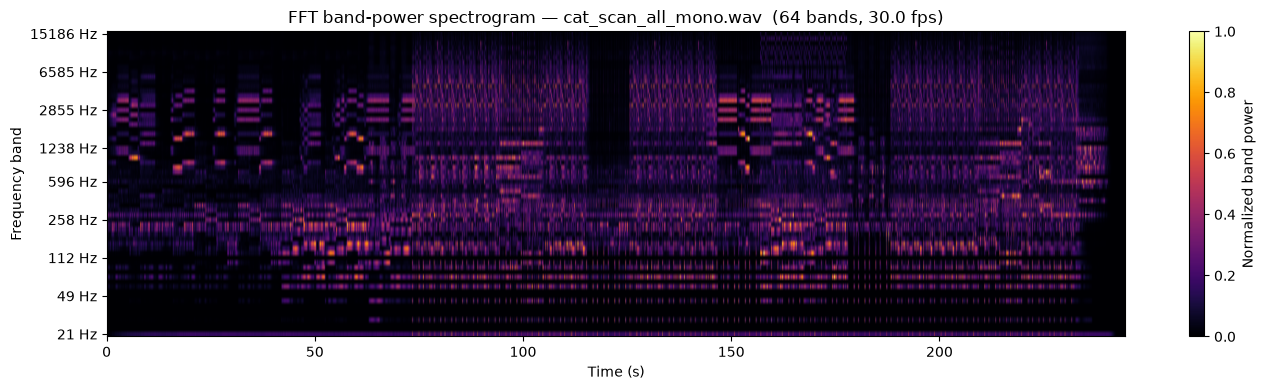

In [18]:
fig, ax = plt.subplots(figsize=(14, 4))

im = ax.imshow(
    tracks.T,         # (bands × frames) — time on x-axis, frequency on y-axis
    aspect="auto",
    origin="lower",   # low-frequency bands at bottom
    cmap="inferno",
    vmin=0, vmax=1,
    extent=[0, duration_s, 0, N_BANDS],
)
plt.colorbar(im, ax=ax, label="Normalized band power")

tick_indices = np.round(np.linspace(0, N_BANDS - 1, 9)).astype(int)
ax.set_yticks(tick_indices + 0.5)
ax.set_yticklabels([f"{band_freqs[i]:.0f} Hz" for i in tick_indices])

ax.set_xlabel("Time (s)")
ax.set_ylabel("Frequency band")
ax.set_title(f"FFT band-power spectrogram — {SOURCE_WAV.name}  ({N_BANDS} bands, {FPS} fps)")
plt.tight_layout()
plt.show()

### 2b. Selected band time series

How four representative bands evolve over the recording — bass, low-mid, mid, and high.
These are the waveforms that drive `translate_z` on each hyperglyph in GlyphViz.

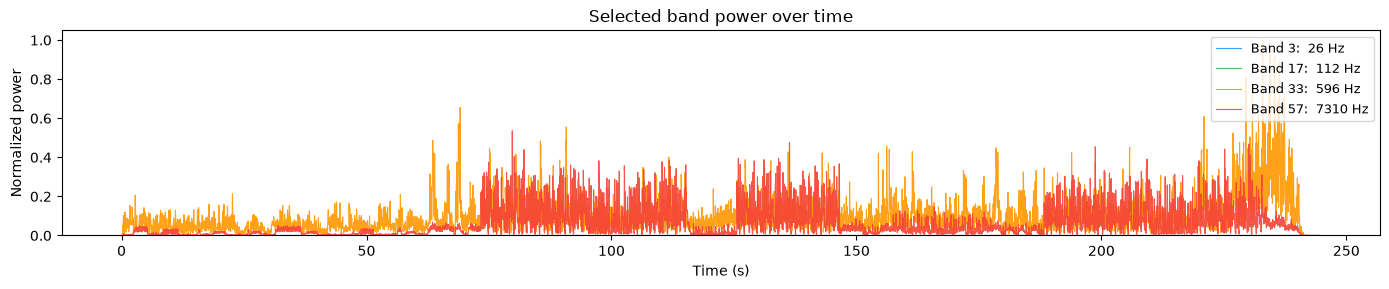

In [19]:
band_picks = [2, 16, 32, 56]   # roughly bass, low-mid, mid, high
band_colors = ["#2196f3", "#4caf50", "#ff9800", "#f44336"]
time_axis = np.linspace(0, duration_s, n_frames)

fig, ax = plt.subplots(figsize=(14, 3))
for band_idx, color in zip(band_picks, band_colors):
    ax.plot(
        time_axis, tracks[:, band_idx],
        label=f"Band {band_idx + 1}:  {band_freqs[band_idx]:.0f} Hz",
        color=color, linewidth=0.8, alpha=0.9,
    )

ax.set_xlabel("Time (s)")
ax.set_ylabel("Normalized power")
ax.set_title("Selected band power over time")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

### 2c. Peak power distribution across bands

Which frequency bands are most active overall? Low-frequency bands dominated by the
bass/cello will peak higher; very high bands tend to tail off.

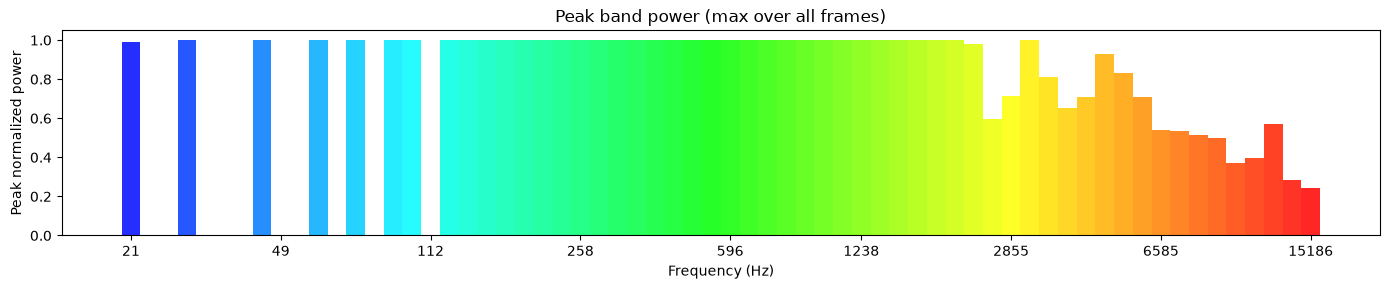

In [20]:
peak_power = tracks.max(axis=0)   # max over time for each band

# Color bars blue → red to match the GlyphViz scene coloring
bar_colors = [
    "#{:02x}{:02x}{:02x}".format(*[int(c * 255) for c in
        colorsys.hsv_to_rgb(0.66 * (1.0 - i / max(N_BANDS - 1, 1)), 0.85, 1.0)])
    for i in range(N_BANDS)
]

fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(range(N_BANDS), peak_power, color=bar_colors, width=1.0, edgecolor="none")

tick_indices = np.round(np.linspace(0, N_BANDS - 1, 9)).astype(int)
ax.set_xticks(tick_indices)
ax.set_xticklabels([f"{band_freqs[i]:.0f}" for i in tick_indices])
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Peak normalized power")
ax.set_title("Peak band power (max over all frames)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## 3. Write GlyphViz files

Generates all five output files in `OUTPUT_DIR`. Output is identical to running
`generate_audio_example.py` directly — the same helper functions are reproduced here
so the notebook is self-contained.

In [21]:
def _band_color(i, n):
    hue = 0.66 * (1.0 - i / max(n - 1, 1))
    r, g, b = colorsys.hsv_to_rgb(hue, 0.85, 1.0)
    return int(r * 255), int(g * 255), int(b * 255)


def _node_row(node_id, parent_id, branch_level, tx, ty, tz, scale, color, geometry, ch_input_id):
    r, g, b = color
    return {
        "id": node_id, "type": 5, "parent_id": parent_id, "branch_level": branch_level,
        "translate_x": round(tx, 4), "translate_y": round(ty, 4), "translate_z": round(tz, 4),
        "rotate_x": 0.0, "rotate_y": 0.0, "rotate_z": 0.0,
        "scale_x": scale, "scale_y": scale, "scale_z": scale,
        "color_r": r, "color_g": g, "color_b": b, "color_a": 255,
        "geometry": geometry, "hide": 0, "topo": TOPO_SPHERE, "ratio": RATIO,
        "ch_input_id": ch_input_id,
    }


def write_nodes(path, bfreqs):
    fieldnames = [
        "id", "type", "parent_id", "branch_level",
        "translate_x", "translate_y", "translate_z",
        "rotate_x", "rotate_y", "rotate_z",
        "scale_x", "scale_y", "scale_z",
        "color_r", "color_g", "color_b", "color_a",
        "geometry", "hide", "topo", "ratio", "ch_input_id",
    ]
    n = len(bfreqs)
    x0 = -(n - 1) / 2.0 * SPACING
    rows = []
    next_id = n + 1
    for i in range(n):
        color = _band_color(i, n)
        ch_id = i + 1
        root_id = i + 1
        rows.append(_node_row(root_id, 0, 0, x0 + i * SPACING, 0.0, 0.0,
                               SCALE, color, GEO_SPHERE_WIRE, ch_id))
        for j in range(N_L1_CHILDREN):
            longitude = j * 360.0 / N_L1_CHILDREN   # evenly around equator
            l1_id = next_id; next_id += 1
            rows.append(_node_row(l1_id, root_id, 1, longitude, 0.0, 0.0,
                                   L1_SCALE, color, _rng.choice(CHILD_GEOMETRIES), ch_id))
            for k in range(N_L2_CHILDREN):
                longitude2 = k * 360.0 / N_L2_CHILDREN
                l2_id = next_id; next_id += 1
                rows.append(_node_row(l2_id, l1_id, 2, longitude2, 0.0, 0.0,
                                       L2_SCALE, color, _rng.choice(CHILD_GEOMETRIES), ch_id))
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fieldnames)
        w.writeheader(); w.writerows(rows)
    print(f"  {path.name}: {len(rows)} nodes")


def write_tags(path, bfreqs):
    rows = [{"id": i, "table_id": 0, "record_id": i + 1, "title": f"{freq:.0f} Hz"}
            for i, freq in enumerate(bfreqs)]
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=["id", "table_id", "record_id", "title"])
        w.writeheader(); w.writerows(rows)
    print(f"  {path.name}: {len(rows)} frequency labels")


def write_ch_map(path, n_bands):
    rows = [{"id": i, "channel_id": i + 1, "track_id": i + 1, "attribute": "translate_z",
             "track_table_id": 0, "ch_map_table_id": 0, "record_id": 0}
            for i in range(n_bands)]
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=["id", "channel_id", "track_id", "attribute",
                                           "track_table_id", "ch_map_table_id", "record_id"])
        w.writeheader(); w.writerows(rows)
    print(f"  {path.name}: {n_bands} channel mappings (-> translate_z)")


def write_ch_tracks(path, tracks_arr):
    n_f, n_b = tracks_arr.shape
    track_cols = [f"ch{i + 1}" for i in range(n_b)]
    rows = []
    for j in range(n_f):
        row = {"cyclecount": j}
        for i in range(n_b):
            row[track_cols[i]] = round(float(tracks_arr[j, i]) * AMPLITUDE, 6)
        rows.append(row)
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=["cyclecount"] + track_cols)
        w.writeheader(); w.writerows(rows)
    print(f"  {path.name}: {n_f} frames × {n_b} tracks  (peak ±{AMPLITUDE})")


def write_audio_manifest(path, wav_path):
    rel = wav_path.resolve().relative_to(OUTPUT_DIR.resolve())
    path.write_text(str(rel).replace("\\", "/") + "\n", encoding="utf-8")
    print(f"  {path.name}: -> {rel}")


print(f"Writing to {OUTPUT_DIR}/\n")
write_nodes         (OUTPUT_DIR / f"{PREFIX}_gv_node.csv",     band_freqs)
write_tags          (OUTPUT_DIR / f"{PREFIX}_gv_tag.csv",       band_freqs)
write_ch_map        (OUTPUT_DIR / f"{PREFIX}_gv_ch-map.csv",    N_BANDS)
write_ch_tracks     (OUTPUT_DIR / f"{PREFIX}_gv_ch-tracks.csv", tracks)
write_audio_manifest(OUTPUT_DIR / f"{PREFIX}_gv_audio.txt",     SOURCE_WAV)
print("\nDone.")

Writing to C:\Users\jsale\source\repos\glyphviz\examples\Audio_Animation_Example/

  Cat_Scan_Example_gv_node.csv: 832 nodes
  Cat_Scan_Example_gv_tag.csv: 64 frequency labels
  Cat_Scan_Example_gv_ch-map.csv: 64 channel mappings (-> translate_z)
  Cat_Scan_Example_gv_ch-tracks.csv: 7338 frames × 64 tracks  (peak ±8.0)
  Cat_Scan_Example_gv_audio.txt: -> media\cat_scan_all_mono.wav

Done.


## Done

Load the scene in GlyphViz:

1. **File > Open Node CSV** → `Audio_Animation_Example_gv_node.csv`
2. The Channels panel loads automatically (64 tracks detected).
3. Press **Play** — audio plays in sync, locked to the real playback position
   (`_ch_tick_audio_synced` in `main_window.py` reads `audio.position_ms()` each
   frame so render-rate fluctuations never cause A/V drift).

**Scene layout:** 64 hyperglyphs spread along X (lowest frequency at −X, highest at +X),
each a 3-level hierarchy of wireframe spheres and random child shapes. Every node in a
band's hierarchy shares the same `ch_input_id`, so the whole glyph pulses together with
that band's energy. Children use `TOPO_SPHERE` so Channels drives `translate_z` as
*altitude above the parent's surface* — completely independent of the lon/lat placement
around the equator, so children visibly pop outward rather than just translating with
their parent as a rigid block.